# Homography threshold evaluation: activity, entropy, and label alignment

This notebook computes homographies for frames in `clip_000`, transfers labels through each homography, and measures how stable/aligned the transferred labels are. It then evaluates whether frame-level activity and spatial entropy correlate with homography quality and alignment quality.

The intended coordinate flow is:

`video/proxy frame label coordinates  →  homography H  →  event frame coordinates`

The main outputs are:

- `frame_stats`: one row per event frame / candidate homography.
- `label_alignment_df`: one row per transformed label per homography.
- `threshold_results`: one row per entropy/activity threshold combination.

In [11]:
# Core imports
import os
import re
import math
import json
from pathlib import Path
from dataclasses import dataclass, asdict

import cv2
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

# Optional, only needed when creating proxy event frames from the RGB/video stream
try:
    import torch
    from snntorch import spikegen
except Exception as e:
    torch = None
    spikegen = None
    print("torch/snntorch unavailable; proxy generation from video will be disabled:", repr(e))

# Optional LightGlue imports. Install/import these in your environment if needed.
try:
    from lightglue import LightGlue, SuperPoint, DISK
    from lightglue.utils import numpy_image_to_torch, rbd
except Exception as e:
    LightGlue = SuperPoint = DISK = numpy_image_to_torch = rbd = None
    print("LightGlue unavailable; homography computation will be disabled until installed/importable:", repr(e))

try:
    from scipy.stats import pearsonr, spearmanr
except Exception:
    pearsonr = spearmanr = None
    print("scipy unavailable; correlations will use pandas only.")

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

## 1. Configuration

Update the paths below. The defaults follow the structure in your reference notebook. This version expects event frames in an H5 file and YOLO-style label files under `labels/clip_000/{frame_idx}.txt`.

In [2]:
# ---- Paths ----
BASE_DIR = Path("//172.16.222.2/tmp/Nora/traffic_flow_data/week_36/box_3/2024_09_10_15_50_59_recordings")
EVENT_FRAMES_PATH = BASE_DIR / "event_frames" / "clip_000_frames.h5"  # change to clip_000_frames.h5 if that is your filename
LABEL_DIR = BASE_DIR / "labels" / "clip_000"

VIDEO_PATH = Path("//172.16.222.2/EBVrecordings/2024-TrafficMonitoring/data_collection/week_36/box3/2024_09_10_15_50_59_recordings/video.avi")
TIMESTAMP_PATH = Path("//172.16.222.2/EBVrecordings/2024-TrafficMonitoring/data_collection/week_36/box3/2024_09_10_15_50_59_recordings/timestamps.csv")

# ---- Output/cache ----
OUT_DIR = Path("homography_threshold_eval_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
H_CACHE = OUT_DIR / "clip_000_homographies.npz"
FRAME_STATS_CSV = OUT_DIR / "clip_000_frame_stats.csv"
ALIGNMENT_CSV = OUT_DIR / "clip_000_label_alignment.csv"
THRESHOLD_CSV = OUT_DIR / "clip_000_threshold_sweep.csv"

# ---- Evaluation knobs ----
CLIP_ID = "clip_000"
DEVICE = "cuda" if torch is not None and torch.cuda.is_available() else "cpu"
EXTRACTOR_NAME = "SuperPoint"  # "SuperPoint" or "DISK"
MAX_KEYPOINTS = 4096
RANSAC_REPROJ_THRESHOLD = 3.0
MIN_MATCHES_FOR_H = 30
MIN_INLIERS_FOR_VALID_H = 30

# Use None for every frame. Use e.g. range(0, 5400, 5) for a faster first pass.
FRAME_INDICES_TO_PROCESS = None

# Label filtering
LABEL_CONF_THRESHOLD = 0.60
BOX_EDGE_PAD = 10
MAX_LABEL_FRAMES = None  # set e.g. 1000 for faster tests; None means all label files

# Metrics
ENTROPY_GRID = (3, 4)
CONSENSUS_METHOD = "median"  # currently median only

print("Device:", DEVICE)
print("Outputs:", OUT_DIR.resolve())

Device: cpu
Outputs: C:\Users\Nora Hulth\Documents\preprocessing\runs\homography_threshold_eval_outputs


## 2. Utility functions

In [3]:
def spatial_entropy(frame, grid=(3, 4), normalize=True):
    """Entropy of activity distribution over a grid. Returns (entropy, cell_counts)."""
    frame = np.asarray(frame)
    if frame.ndim != 2:
        raise ValueError(f"Expected a 2D frame, got shape {frame.shape}")

    h, w = frame.shape
    gh, gw = grid
    ys = np.linspace(0, h, gh + 1, dtype=int)
    xs = np.linspace(0, w, gw + 1, dtype=int)

    cell_counts = []
    for i in range(gh):
        for j in range(gw):
            cell_counts.append(frame[ys[i]:ys[i+1], xs[j]:xs[j+1]].sum())

    cell_counts = np.asarray(cell_counts, dtype=float)
    total = cell_counts.sum()
    if total <= 0:
        return 0.0, cell_counts

    p = cell_counts / total
    p = p[p > 0]
    H = -(p * np.log2(p)).sum()
    if normalize:
        H_max = np.log2(gh * gw)
        H = H / H_max if H_max > 0 else 0.0
    return float(H), cell_counts


def event_to_gray_uint8(img):
    """Normalize any event/proxy image to uint8 grayscale for feature matching."""
    img = np.asarray(img, np.float32)
    img = img - np.nanmin(img)
    mx = np.nanmax(img)
    if mx > 0:
        img = img * (255.0 / mx)
    return np.nan_to_num(img).astype(np.uint8)


def activity_fraction(frame):
    """Fraction of nonzero/summed event activity relative to pixels.
    If your frames are binary, this is simply active-pixel fraction.
    """
    frame = np.asarray(frame)
    return float(frame.sum() / frame.size)


def box_inside_frame(corners_xy, W, H, pad=10):
    corners_xy = np.asarray(corners_xy)
    xs = corners_xy[:, 0]
    ys = corners_xy[:, 1]
    return bool((xs >= pad).all() and (xs <= W - pad).all() and (ys >= pad).all() and (ys <= H - pad).all())


def yolo_box_to_corners(x, y, w, h, W, H):
    """YOLO normalized center-x, center-y, width, height -> 4 pixel corners."""
    x, y, w, h = float(x) * W, float(y) * H, float(w) * W, float(h) * H
    return np.float32([
        [x - w/2, y - h/2],
        [x + w/2, y - h/2],
        [x + w/2, y + h/2],
        [x - w/2, y + h/2],
    ])


def transform_corners(corners_xy, H):
    if H is None or not np.isfinite(H).all():
        return None
    pts = np.asarray(corners_xy, np.float32).reshape(-1, 1, 2)
    return cv2.perspectiveTransform(pts, H).reshape(-1, 2)


def corners_to_xyxy(corners):
    corners = np.asarray(corners)
    return np.array([corners[:, 0].min(), corners[:, 1].min(), corners[:, 0].max(), corners[:, 1].max()], dtype=float)


def box_iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    denom = area_a + area_b - inter
    return float(inter / denom) if denom > 0 else np.nan

## 3. Load event frames and compute per-frame activity / entropy

In [5]:
def load_event_frames(path):
    path = Path(path)
    with h5py.File(path, "r") as f:
        if "frames" not in f:
            raise KeyError(f"Expected dataset 'frames' in {path}. Available keys: {list(f.keys())}")
        frames = f["frames"][:]
    if frames.ndim != 3:
        raise ValueError(f"Expected frames with shape (T,H,W), got {frames.shape}")
    return frames

frames = load_event_frames(EVENT_FRAMES_PATH)
T, H_event, W_event = frames.shape
print("frames:", frames.shape)

if FRAME_INDICES_TO_PROCESS is None:
    frame_indices = np.arange(T)
else:
    frame_indices = np.array(list(FRAME_INDICES_TO_PROCESS), dtype=int)
    frame_indices = frame_indices[(frame_indices >= 0) & (frame_indices < T)]

rows = []
for idx in frame_indices:
    ent, counts = spatial_entropy(frames[idx], ENTROPY_GRID)
    rows.append({
        "frame_idx": int(idx),
        "activity": activity_fraction(frames[idx]),
        "entropy": ent,
        "nonzero_pixels": int(np.count_nonzero(frames[idx])),
        "sum_activity": float(frames[idx].sum()),
    })
frame_stats = pd.DataFrame(rows)
frame_stats.head(), frame_stats.describe()

frames: (5400, 480, 640)


(   frame_idx  activity   entropy  nonzero_pixels  sum_activity
 0          0  0.010687  0.856371            3283        3283.0
 1          1  0.009160  0.862906            2814        2814.0
 2          2  0.016719  0.940713            5136        5136.0
 3          3  0.016826  0.938856            5169        5169.0
 4          4  0.018910  0.965378            5809        5809.0,
          frame_idx     activity      entropy  nonzero_pixels  sum_activity
 count  5400.000000  5400.000000  5400.000000     5400.000000   5400.000000
 mean   2699.500000     0.018821     0.759478     5781.940556   5781.940556
 std    1558.990058     0.028741     0.138230     8829.311971   8829.311971
 min       0.000000     0.001572     0.344750      483.000000    483.000000
 25%    1349.750000     0.005790     0.650139     1778.750000   1778.750000
 50%    2699.500000     0.009160     0.751870     2814.000000   2814.000000
 75%    4049.250000     0.016593     0.890793     5097.250000   5097.250000
 max   

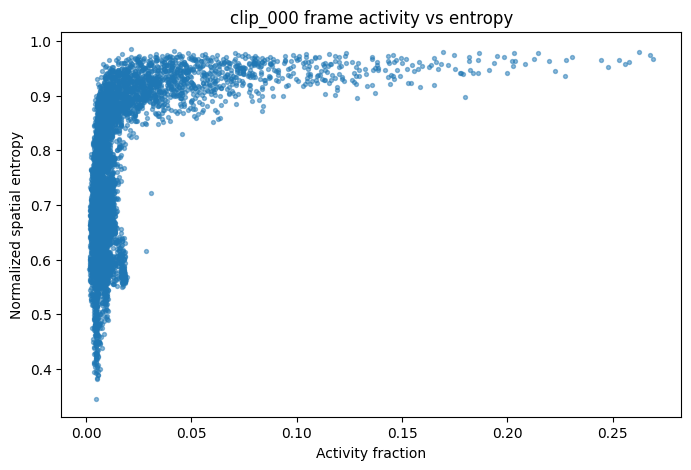

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(frame_stats["activity"], frame_stats["entropy"], s=8, alpha=0.5)
ax.set_xlabel("Activity fraction")
ax.set_ylabel("Normalized spatial entropy")
ax.set_title("clip_000 frame activity vs entropy")
plt.show()

## 4. Build proxy event frames from the RGB/video stream

This reproduces the idea in your reference notebook: create a proxy event image from neighboring RGB video frames via delta spikes, then match `proxy_img -> event_frame`. If you already have proxy frames saved elsewhere, replace this section with a loader that returns `spike_dict[idx]` for each event `idx`.

In [7]:
def infer_shift_from_timestamps(timestamp_path):
    df_timestamps = pd.read_csv(timestamp_path)
    if "event_time" not in df_timestamps.columns:
        raise KeyError("timestamps.csv must contain an 'event_time' column")
    nonzero = df_timestamps.index[df_timestamps["event_time"] != 0]
    if len(nonzero) == 0:
        raise ValueError("Could not infer SHIFT: no nonzero event_time rows")
    return int(nonzero[0])


def build_spike_dict_from_video(video_path, timestamp_path, event_indices, delta_threshold=8):
    if torch is None or spikegen is None:
        raise RuntimeError("torch/snntorch is required for proxy generation")

    shift = infer_shift_from_timestamps(timestamp_path)
    event_indices = set(int(i) for i in event_indices)

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    # Skip to event/video alignment point.
    t = 0
    ret, frame = cap.read()
    if not ret:
        raise RuntimeError("Empty video")
    while t < shift:
        ret, frame = cap.read()
        if not ret:
            raise RuntimeError(f"Video ended before SHIFT={shift}")
        t += 1

    spike_dict = {}
    prev_gray = None
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(np.float32)
    i = 0

    while True:
        ret, next_frame = cap.read()
        if not ret:
            break
        next_gray = cv2.cvtColor(next_frame, cv2.COLOR_BGR2GRAY).astype(np.float32)

        if i in event_indices:
            if prev_gray is None:
                # Fallback for first frame: use absolute difference to next frame.
                proxy = np.abs(next_gray - gray)
                spike_dict[i] = (proxy > delta_threshold).astype(np.uint8)
            else:
                data = torch.from_numpy(np.stack([prev_gray, gray, next_gray], axis=0)).to(torch.float32)
                spikes = spikegen.delta(data, threshold=delta_threshold)
                sp = spikes[1:].cpu().numpy() if torch.is_tensor(spikes) else spikes
                spike_dict[i] = (sp > 0).any(axis=0).astype(np.uint8)

        prev_gray, gray = gray, next_gray
        i += 1
        if i > max(event_indices, default=-1):
            break

    cap.release()
    missing = sorted(event_indices - set(spike_dict.keys()))
    if missing:
        print(f"Warning: {len(missing)} requested proxy frames were not generated. First missing: {missing[:10]}")
    return spike_dict

spike_dict = build_spike_dict_from_video(VIDEO_PATH, TIMESTAMP_PATH, frame_indices, delta_threshold=8)
print("proxy frames generated:", len(spike_dict))

proxy frames generated: 5400


## 5. Compute homographies for all selected clip_000 frames

Each homography maps from proxy/video-label coordinates into event-frame coordinates. Results are cached so the expensive matching step does not have to be repeated.

In [8]:
def build_lightglue_models(extractor_name="SuperPoint", device="cpu", max_kpts=4096):
    if LightGlue is None or numpy_image_to_torch is None or rbd is None:
        raise RuntimeError("LightGlue imports are unavailable")

    extractor_name = extractor_name.lower()
    if extractor_name == "superpoint":
        extractor = SuperPoint(max_num_keypoints=max_kpts).eval().to(device)
        matcher = LightGlue(features="superpoint").eval().to(device)
    elif extractor_name == "disk":
        extractor = DISK(max_num_keypoints=max_kpts).eval().to(device)
        matcher = LightGlue(features="disk").eval().to(device)
    else:
        raise ValueError("EXTRACTOR_NAME must be 'SuperPoint' or 'DISK'")
    return extractor, matcher


def preprocess_lightglue(img):
    return numpy_image_to_torch(event_to_gray_uint8(img))


def match_lightglue(img0, img1, extractor, matcher, device="cpu"):
    """Match img0 -> img1. Returns matched keypoints in original image coordinates."""
    image0 = preprocess_lightglue(img0).to(device)
    image1 = preprocess_lightglue(img1).to(device)
    with torch.no_grad():
        feats0 = extractor.extract(image0)
        feats1 = extractor.extract(image1)
        matches01 = matcher({"image0": feats0, "image1": feats1})
    feats0, feats1, matches01 = [rbd(x) for x in [feats0, feats1, matches01]]
    matches = matches01["matches"]
    kpts0 = feats0["keypoints"]
    kpts1 = feats1["keypoints"]
    mkpts0 = kpts0[matches[..., 0]].detach().cpu().numpy()
    mkpts1 = kpts1[matches[..., 1]].detach().cpu().numpy()
    return {
        "kpts0": kpts0.detach().cpu().numpy(),
        "kpts1": kpts1.detach().cpu().numpy(),
        "matches": matches.detach().cpu().numpy(),
        "mkpts0": mkpts0,
        "mkpts1": mkpts1,
    }


def homography_from_matches(match_result, ransac_reproj_threshold=3.0, min_matches=30):
    pts0 = np.asarray(match_result["mkpts0"], np.float32)
    pts1 = np.asarray(match_result["mkpts1"], np.float32)
    if len(pts0) < min_matches:
        return None, None, np.nan, np.nan
    H, mask = cv2.findHomography(pts0, pts1, cv2.RANSAC, ransac_reproj_threshold)
    if H is None or mask is None:
        return None, mask, np.nan, np.nan

    inlier = mask.ravel().astype(bool)
    if inlier.sum() > 0:
        pred = cv2.perspectiveTransform(pts0[inlier].reshape(-1, 1, 2), H).reshape(-1, 2)
        reproj = np.linalg.norm(pred - pts1[inlier], axis=1)
        mean_reproj = float(reproj.mean())
        median_reproj = float(np.median(reproj))
    else:
        mean_reproj = median_reproj = np.nan
    return H, mask, mean_reproj, median_reproj


def compute_or_load_homographies(frames, spike_dict, frame_stats, cache_path):
    cache_path = Path(cache_path)
    if cache_path.exists():
        data = np.load(cache_path, allow_pickle=True)
        Hs = data["Hs"]
        cached_stats = pd.read_csv(FRAME_STATS_CSV) if Path(FRAME_STATS_CSV).exists() else frame_stats.copy()
        print(f"Loaded cached homographies: {cache_path}")
        return Hs, cached_stats

    extractor, matcher = build_lightglue_models(EXTRACTOR_NAME, DEVICE, MAX_KEYPOINTS)
    Hs = []
    extra_rows = []

    for _, row in frame_stats.iterrows():
        idx = int(row["frame_idx"])
        print(f"Processing homography for frame {idx}")
        proxy = spike_dict.get(idx)
        if proxy is None:
            Hs.append(np.full((3, 3), np.nan, dtype=float))
            extra_rows.append({"frame_idx": idx, "num_matches": 0, "num_inliers": 0, "inlier_ratio": np.nan, "mean_reproj_px": np.nan, "median_reproj_px": np.nan, "valid_h": False})
            continue

        try:
            m = match_lightglue(proxy, frames[idx], extractor, matcher, DEVICE)
            H, mask, mean_r, median_r = homography_from_matches(m, RANSAC_REPROJ_THRESHOLD, MIN_MATCHES_FOR_H)
            num_matches = int(len(m["mkpts0"]))
            num_inliers = int(mask.ravel().sum()) if mask is not None else 0
            valid = H is not None and num_inliers >= MIN_INLIERS_FOR_VALID_H
            Hs.append(H if H is not None else np.full((3, 3), np.nan, dtype=float))
            extra_rows.append({
                "frame_idx": idx,
                "num_matches": num_matches,
                "num_inliers": num_inliers,
                "inlier_ratio": float(num_inliers / num_matches) if num_matches else np.nan,
                "mean_reproj_px": mean_r,
                "median_reproj_px": median_r,
                "valid_h": bool(valid),
            })
        except Exception as e:
            print(f"Failed frame {idx}: {e}")
            Hs.append(np.full((3, 3), np.nan, dtype=float))
            extra_rows.append({"frame_idx": idx, "num_matches": 0, "num_inliers": 0, "inlier_ratio": np.nan, "mean_reproj_px": np.nan, "median_reproj_px": np.nan, "valid_h": False})

    Hs = np.stack(Hs, axis=0)
    extra = pd.DataFrame(extra_rows)
    merged = frame_stats.merge(extra, on="frame_idx", how="left")
    np.savez_compressed(cache_path, Hs=Hs, frame_indices=frame_stats["frame_idx"].to_numpy())
    merged.to_csv(FRAME_STATS_CSV, index=False)
    return Hs, merged

Hs, frame_stats = compute_or_load_homographies(frames, spike_dict, frame_stats, H_CACHE)
print(Hs.shape)
frame_stats.head()

Loaded cached homographies: homography_threshold_eval_outputs\clip_000_homographies.npz
(5400, 3, 3)


,frame_idx,activity,entropy,nonzero_pixels,sum_activity,num_matches,num_inliers,inlier_ratio,mean_reproj_px,median_reproj_px,valid_h
0,0,0.010687,0.856371,3283,3283.0,399,192,0.481203,1.709553,1.714172,True
1,1,0.009160,0.862906,2814,2814.0,9,0,0.000000,NaN,NaN,False
2,2,0.016719,0.940713,5136,5136.0,652,294,0.450920,1.796573,1.878897,True
3,3,0.016826,0.938856,5169,5169.0,16,0,0.000000,NaN,NaN,False
4,4,0.018910,0.965378,5809,5809.0,870,419,0.481609,1.726145,1.722543,True


## 6. Transfer labels and measure alignment

For each label, the same source box is transformed by every valid homography. A robust median of transformed corners is used as a consensus target. The error for each homography is the distance from its transformed box to that consensus.

This evaluates whether a homography computed from a frame with certain activity/entropy produces labels that agree with the rest of the homographies.

In [13]:
def read_yolo_label_file(path, conf_thr=0.6):
    path = Path(path)

    if not path.exists():
        return []

    if not path.is_file():
        print("Skipping non-file:", repr(str(path)))
        return []

    out = []
    try:
        text = path.read_text(encoding="utf-8", errors="replace")
    except OSError as e:
        print("Could not read label file:", repr(str(path)), e)
        return []

    for line_no, s in enumerate(text.splitlines()):
        parts = s.split()
        if len(parts) < 5:
            continue

        cls = parts[0]
        x, y, w, h = map(float, parts[1:5])
        conf = float(parts[5]) if len(parts) >= 6 else 1.0

        if conf < conf_thr:
            continue

        out.append({
            "class": cls,
            "x": x,
            "y": y,
            "w": w,
            "h": h,
            "conf": conf,
            "line_no": line_no,
        })

    return out


def compute_label_alignment(Hs, frame_stats, label_dir, W_source, H_source, W_target, H_target, conf_thr=0.6, pad=10, max_label_frames=None):
    valid_rows = frame_stats.reset_index(drop=True).copy()
    valid_rows["h_array_idx"] = np.arange(len(valid_rows))
    valid_rows = valid_rows[valid_rows["valid_h"].fillna(False)].copy()

    if len(valid_rows) < 2:
        raise RuntimeError("Need at least two valid homographies to measure alignment dispersion.")

    label_files = sorted(Path(label_dir).glob("*.txt"), key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem)
    if max_label_frames is not None:
        label_files = label_files[:max_label_frames]

    records = []
    skipped_no_consensus = 0

    sample_idxs = random.sample(range(1, 5400), 100)

    for idx in sample_idxs:
        lf = label_files[idx]
        try:
            label_frame_idx = int(lf.stem)
        except ValueError:
            label_frame_idx = lf.stem
        labels = read_yolo_label_file(lf, conf_thr)
        if not labels:
            continue

        for label_local_idx, lab in enumerate(labels):
            source_corners = yolo_box_to_corners(lab["x"], lab["y"], lab["w"], lab["h"], W_source, H_source)

            transformed = []
            meta = []
            for _, hr in valid_rows.iterrows():
                h_idx = int(hr["h_array_idx"])
                corners_t = transform_corners(source_corners, Hs[h_idx])
                if corners_t is None:
                    continue
                if not box_inside_frame(corners_t, W_target, H_target, pad=pad):
                    continue
                transformed.append(corners_t)
                meta.append(hr)

            if len(transformed) < 2:
                skipped_no_consensus += 1
                continue

            arr = np.stack(transformed, axis=0)  # nH, 4, 2
            consensus = np.median(arr, axis=0)
            consensus_xyxy = corners_to_xyxy(consensus)

            for corners_t, hr in zip(transformed, meta):
                corner_l2 = np.linalg.norm(corners_t - consensus, axis=1)
                corner_l1 = np.abs(corners_t - consensus).sum(axis=1)
                xyxy = corners_to_xyxy(corners_t)
                records.append({
                    "label_frame_idx": label_frame_idx,
                    "label_local_idx": int(label_local_idx),
                    "label_global_id": f"{label_frame_idx}_{label_local_idx}",
                    "class": lab["class"],
                    "conf": lab["conf"],
                    "homography_frame_idx": int(hr["frame_idx"]),
                    "activity": float(hr["activity"]),
                    "entropy": float(hr["entropy"]),
                    "num_matches": float(hr.get("num_matches", np.nan)),
                    "num_inliers": float(hr.get("num_inliers", np.nan)),
                    "inlier_ratio": float(hr.get("inlier_ratio", np.nan)),
                    "mean_reproj_px": float(hr.get("mean_reproj_px", np.nan)),
                    "median_reproj_px": float(hr.get("median_reproj_px", np.nan)),
                    "mean_corner_l2_px": float(corner_l2.mean()),
                    "median_corner_l2_px": float(np.median(corner_l2)),
                    "mean_corner_l1_px": float(corner_l1.mean()),
                    "iou_to_consensus": box_iou_xyxy(xyxy, consensus_xyxy),
                    "n_homographies_for_label": int(len(transformed)),
                })

    print(f"Skipped labels with <2 in-frame transforms: {skipped_no_consensus}")
    return pd.DataFrame(records)

# Source dimensions are the proxy/video dimensions. Use a generated proxy if available.
example_proxy = next(iter(spike_dict.values()))
H_source, W_source = example_proxy.shape[-2:]
H_target, W_target = frames.shape[-2:]

label_alignment_df = compute_label_alignment(
    Hs=Hs,
    frame_stats=frame_stats,
    label_dir=LABEL_DIR,
    W_source=W_source,
    H_source=H_source,
    W_target=W_target,
    H_target=H_target,
    conf_thr=LABEL_CONF_THRESHOLD,
    pad=BOX_EDGE_PAD,
    max_label_frames=MAX_LABEL_FRAMES,
)
label_alignment_df.to_csv(ALIGNMENT_CSV, index=False)
print(label_alignment_df.shape)
label_alignment_df.head()

Skipped labels with <2 in-frame transforms: 107
(1922579, 18)


,label_frame_idx,label_local_idx,label_global_id,class,conf,homography_frame_idx,activity,entropy,num_matches,num_inliers,inlier_ratio,mean_reproj_px,median_reproj_px,mean_corner_l2_px,median_corner_l2_px,mean_corner_l1_px,iou_to_consensus,n_homographies_for_label
0,4816,0,4816_0,2,0.865788,0,0.010687,0.856371,399.0,192.0,0.481203,1.709553,1.714172,0.628448,0.651106,0.825907,0.952616,2995
1,4816,0,4816_0,2,0.865788,2,0.016719,0.940713,652.0,294.0,0.450920,1.796573,1.878897,1.506288,1.479663,1.703302,0.907503,2995
2,4816,0,4816_0,2,0.865788,4,0.018910,0.965378,870.0,419.0,0.481609,1.726145,1.722543,0.862527,0.860469,1.010546,0.937570,2995
3,4816,0,4816_0,2,0.865788,5,0.011829,0.921817,652.0,300.0,0.460123,1.788231,1.850031,2.003259,2.003042,2.512344,0.865897,2995
4,4816,0,4816_0,2,0.865788,6,0.018740,0.946821,908.0,494.0,0.544053,1.735393,1.763375,1.356415,1.341873,1.869078,0.895813,2995


## 7. Summarize homography quality per candidate frame

In [15]:
per_h = (
    label_alignment_df
    .groupby("homography_frame_idx")
    .agg(
        n_labels=("label_global_id", "count"),
        mean_alignment_error_px=("mean_corner_l2_px", "mean"),
        median_alignment_error_px=("mean_corner_l2_px", "median"),
        p90_alignment_error_px=("mean_corner_l2_px", lambda s: np.nanpercentile(s, 90)),
        mean_iou_to_consensus=("iou_to_consensus", "mean"),
    )
    .reset_index()
    .rename(columns={"homography_frame_idx": "frame_idx"})
)

frame_quality = frame_stats.merge(per_h, on="frame_idx", how="left")
frame_quality.to_csv(OUT_DIR / "clip_000_frame_quality.csv", index=False)
frame_quality.sort_values("median_alignment_error_px").head(20)

,frame_idx,activity,entropy,nonzero_pixels,sum_activity,num_matches,num_inliers,inlier_ratio,mean_reproj_px,median_reproj_px,valid_h,n_labels,mean_alignment_error_px,median_alignment_error_px,p90_alignment_error_px,mean_iou_to_consensus
5178,5178,0.029893,0.904455,9183,9183.0,978,608,0.621677,1.668100,1.676528,True,645.0,0.689022,0.294776,1.596767,0.954692
3978,3978,0.033812,0.917686,10387,10387.0,1105,705,0.638009,1.761495,1.805914,True,643.0,0.671596,0.309946,1.714270,0.953852
304,304,0.038740,0.930997,11901,11901.0,1175,863,0.734468,1.698615,1.727924,True,645.0,0.749821,0.330898,2.085076,0.948328
488,488,0.115348,0.922935,35435,35435.0,1484,1077,0.725741,1.618088,1.640301,True,646.0,0.783667,0.341865,1.794259,0.951585
390,390,0.111973,0.931436,34398,34398.0,1511,986,0.652548,1.617303,1.617556,True,643.0,0.512274,0.371098,0.691772,0.959906
363,363,0.079779,0.968454,24508,24508.0,1406,888,0.631579,1.710618,1.706742,True,644.0,0.777461,0.373627,1.605302,0.948985
3896,3896,0.040514,0.911822,12446,12446.0,1109,657,0.592426,1.702297,1.739195,True,641.0,0.528439,0.374166,0.758270,0.959483
3302,3302,0.017132,0.875213,5263,5263.0,711,366,0.514768,1.749428,1.809139,True,632.0,1.190713,0.388018,5.326032,0.921999
3788,3788,0.021800,0.892379,6697,6697.0,857,471,0.549592,1.676111,1.724497,True,645.0,0.826423,0.395230,2.106412,0.952386
253,253,0.149238,0.968652,45846,45846.0,1412,943,0.667847,1.656975,1.692846,True,644.0,0.689791,0.395988,1.321345,0.947632


In [16]:
cols = ["activity", "entropy", "num_matches", "num_inliers", "inlier_ratio", "mean_reproj_px", "median_alignment_error_px", "mean_iou_to_consensus"]
print(frame_quality[cols].corr(numeric_only=True))

if pearsonr is not None and spearmanr is not None:
    for x in ["activity", "entropy", "num_matches", "num_inliers", "inlier_ratio", "mean_reproj_px"]:
        tmp = frame_quality[[x, "median_alignment_error_px"]].dropna()
        if len(tmp) >= 3:
            pr = pearsonr(tmp[x], tmp["median_alignment_error_px"])
            sr = spearmanr(tmp[x], tmp["median_alignment_error_px"])
            print(f"{x:>18} vs median_alignment_error_px | Pearson r={pr.statistic: .3f}, p={pr.pvalue:.3g} | Spearman rho={sr.statistic: .3f}, p={sr.pvalue:.3g}")

                           activity   entropy  num_matches  num_inliers  inlier_ratio  mean_reproj_px  median_alignment_error_px  mean_iou_to_consensus
activity                   1.000000  0.500496     0.765248     0.785273      0.434463        0.200948                  -0.194636               0.380208
entropy                    0.500496  1.000000     0.611412     0.597486      0.243914        0.191975                  -0.378138               0.636975
num_matches                0.765248  0.611412     1.000000     0.992036      0.662177        0.430250                  -0.358987               0.651089
num_inliers                0.785273  0.597486     0.992036     1.000000      0.647414        0.380042                  -0.333139               0.615826
inlier_ratio               0.434463  0.243914     0.662177     0.647414      1.000000        0.305241                  -0.189061               0.354819
mean_reproj_px             0.200948  0.191975     0.430250     0.380042      0.305241   

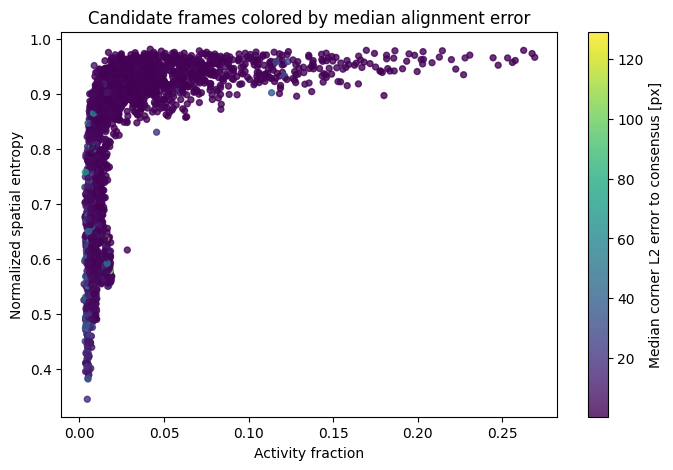

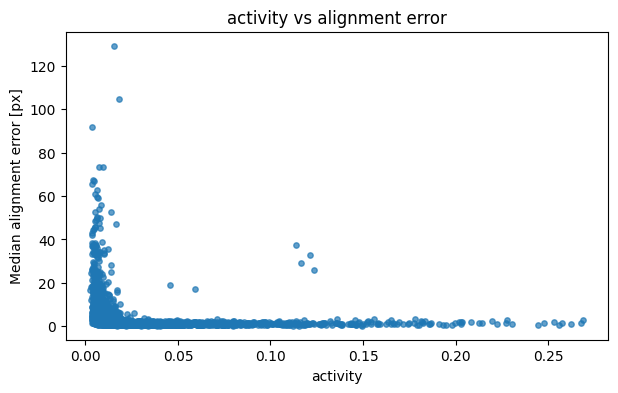

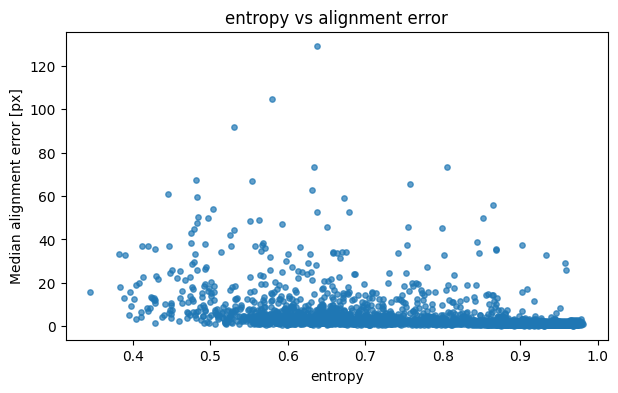

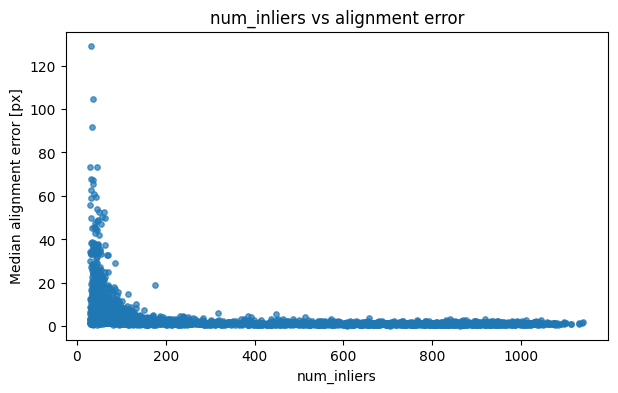

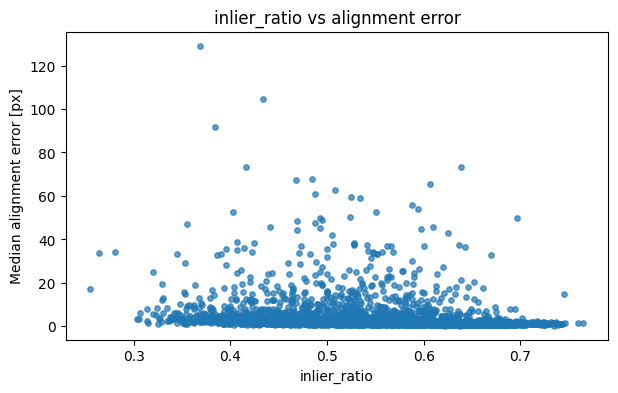

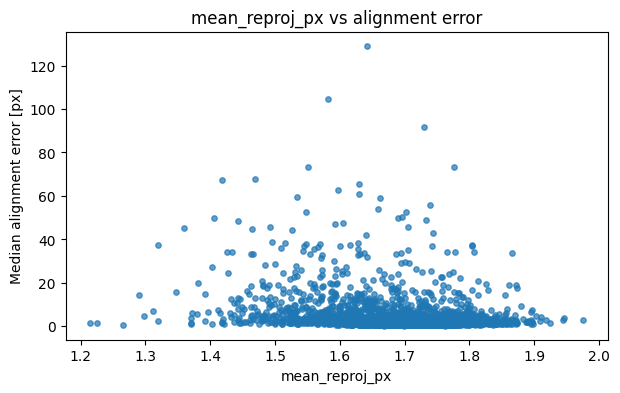

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(frame_quality["activity"], frame_quality["entropy"], c=frame_quality["median_alignment_error_px"], s=18, alpha=0.8)
ax.set_xlabel("Activity fraction")
ax.set_ylabel("Normalized spatial entropy")
ax.set_title("Candidate frames colored by median alignment error")
plt.colorbar(sc, ax=ax, label="Median corner L2 error to consensus [px]")
plt.show()

for x in ["activity", "entropy", "num_inliers", "inlier_ratio", "mean_reproj_px"]:
    if x not in frame_quality:
        continue
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(frame_quality[x], frame_quality["median_alignment_error_px"], s=15, alpha=0.7)
    ax.set_xlabel(x)
    ax.set_ylabel("Median alignment error [px]")
    ax.set_title(f"{x} vs alignment error")
    plt.show()

## 8. Threshold sweep: activity and entropy

This tests many selection rules and reports the alignment quality of the homographies that pass each rule. Adjust the threshold grids to match the range you care about.

In [18]:
def threshold_sweep(frame_quality, min_selected=3):
    activity_mins = np.linspace(frame_quality["activity"].quantile(0.02), frame_quality["activity"].quantile(0.60), 12)
    activity_maxs = np.linspace(frame_quality["activity"].quantile(0.40), frame_quality["activity"].quantile(0.98), 12)
    entropy_mins = np.linspace(frame_quality["entropy"].quantile(0.02), frame_quality["entropy"].quantile(0.80), 12)
    entropy_maxs = np.linspace(frame_quality["entropy"].quantile(0.50), frame_quality["entropy"].quantile(0.995), 12)

    rows = []
    fq = frame_quality.copy()
    fq = fq[fq["valid_h"].fillna(False) & fq["median_alignment_error_px"].notna()]

    for a_min in activity_mins:
        for a_max in activity_maxs:
            if a_min >= a_max:
                continue
            for e_min in entropy_mins:
                for e_max in entropy_maxs:
                    if e_min >= e_max:
                        continue
                    sel = fq[
                        (fq["activity"] >= a_min) & (fq["activity"] <= a_max) &
                        (fq["entropy"] >= e_min) & (fq["entropy"] <= e_max)
                    ]
                    if len(sel) < min_selected:
                        continue
                    rows.append({
                        "activity_min": float(a_min),
                        "activity_max": float(a_max),
                        "entropy_min": float(e_min),
                        "entropy_max": float(e_max),
                        "n_selected": int(len(sel)),
                        "median_alignment_error_px": float(sel["median_alignment_error_px"].median()),
                        "mean_alignment_error_px": float(sel["mean_alignment_error_px"].mean()),
                        "p90_alignment_error_px": float(sel["p90_alignment_error_px"].median()),
                        "mean_iou_to_consensus": float(sel["mean_iou_to_consensus"].mean()),
                        "median_num_inliers": float(sel["num_inliers"].median()),
                        "median_reproj_px": float(sel["mean_reproj_px"].median()),
                    })
    return pd.DataFrame(rows).sort_values(["median_alignment_error_px", "p90_alignment_error_px"])

threshold_results = threshold_sweep(frame_quality, min_selected=3)
threshold_results.to_csv(THRESHOLD_CSV, index=False)
threshold_results.head(20)

,activity_min,activity_max,entropy_min,entropy_max,n_selected,median_alignment_error_px,mean_alignment_error_px,p90_alignment_error_px,mean_iou_to_consensus,median_num_inliers,median_reproj_px
16192,0.010697,0.048154,0.905705,0.973526,464,1.062804,1.742020,3.662321,0.885928,650.5,1.729684
16315,0.010697,0.058267,0.905705,0.973526,534,1.067612,1.711158,3.604580,0.887492,684.5,1.725570
7562,0.006240,0.017815,0.790703,0.792171,4,1.067729,1.921725,5.627392,0.868154,191.0,1.735075
7685,0.006240,0.027928,0.790703,0.792171,4,1.067729,1.921725,5.627392,0.868154,191.0,1.735075
7808,0.006240,0.038041,0.790703,0.792171,4,1.067729,1.921725,5.627392,0.868154,191.0,1.735075
7931,0.006240,0.048154,0.790703,0.792171,4,1.067729,1.921725,5.627392,0.868154,191.0,1.735075
8054,0.006240,0.058267,0.790703,0.792171,4,1.067729,1.921725,5.627392,0.868154,191.0,1.735075
8177,0.006240,0.068380,0.790703,0.792171,4,1.067729,1.921725,5.627392,0.868154,191.0,1.735075
8300,0.006240,0.078493,0.790703,0.792171,4,1.067729,1.921725,5.627392,0.868154,191.0,1.735075
8423,0.006240,0.088606,0.790703,0.792171,4,1.067729,1.921725,5.627392,0.868154,191.0,1.735075


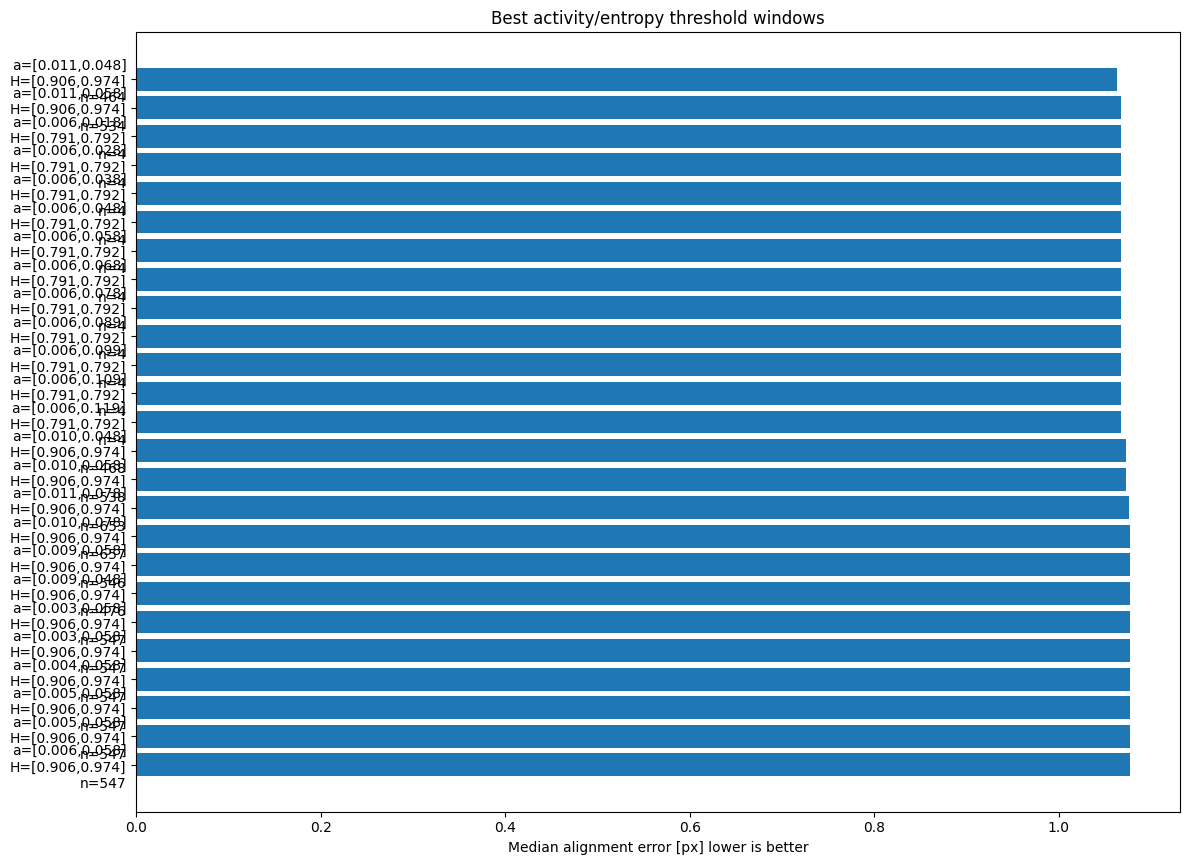

In [19]:
# Visualize the best threshold windows.
show_n = min(25, len(threshold_results))
plot_df = threshold_results.head(show_n).copy()
plot_df["rule"] = [
    f"a=[{r.activity_min:.3f},{r.activity_max:.3f}]\nH=[{r.entropy_min:.3f},{r.entropy_max:.3f}]\nn={int(r.n_selected)}"
    for _, r in plot_df.iterrows()
]

fig, ax = plt.subplots(figsize=(12, max(5, show_n * 0.35)))
y = np.arange(show_n)
ax.barh(y, plot_df["median_alignment_error_px"])
ax.set_yticks(y)
ax.set_yticklabels(plot_df["rule"])
ax.invert_yaxis()
ax.set_xlabel("Median alignment error [px] lower is better")
ax.set_title("Best activity/entropy threshold windows")
plt.tight_layout()
plt.show()

## 9. Inspect a threshold rule and visualize selected frames

Selected 464 homographies with activity=[0.0107,0.0482], entropy=[0.9057,0.9735]


,frame_idx,activity,entropy,num_inliers,mean_reproj_px,median_alignment_error_px,mean_iou_to_consensus
3978,3978,0.033812,0.917686,705,1.761495,0.309946,0.953852
304,304,0.038740,0.930997,863,1.698615,0.330898,0.948328
3896,3896,0.040514,0.911822,657,1.702297,0.374166,0.959483
3761,3761,0.039548,0.925113,754,1.749229,0.425072,0.944922
97,97,0.027305,0.951071,759,1.698782,0.432572,0.949390
3578,3578,0.015671,0.911434,287,1.724785,0.435200,0.927551
486,486,0.033327,0.971215,566,1.680997,0.441647,0.951733
331,331,0.018418,0.960313,434,1.677976,0.444058,0.884727
66,66,0.038076,0.968135,805,1.645123,0.447425,0.947417
3708,3708,0.027705,0.941698,582,1.707039,0.456784,0.939267


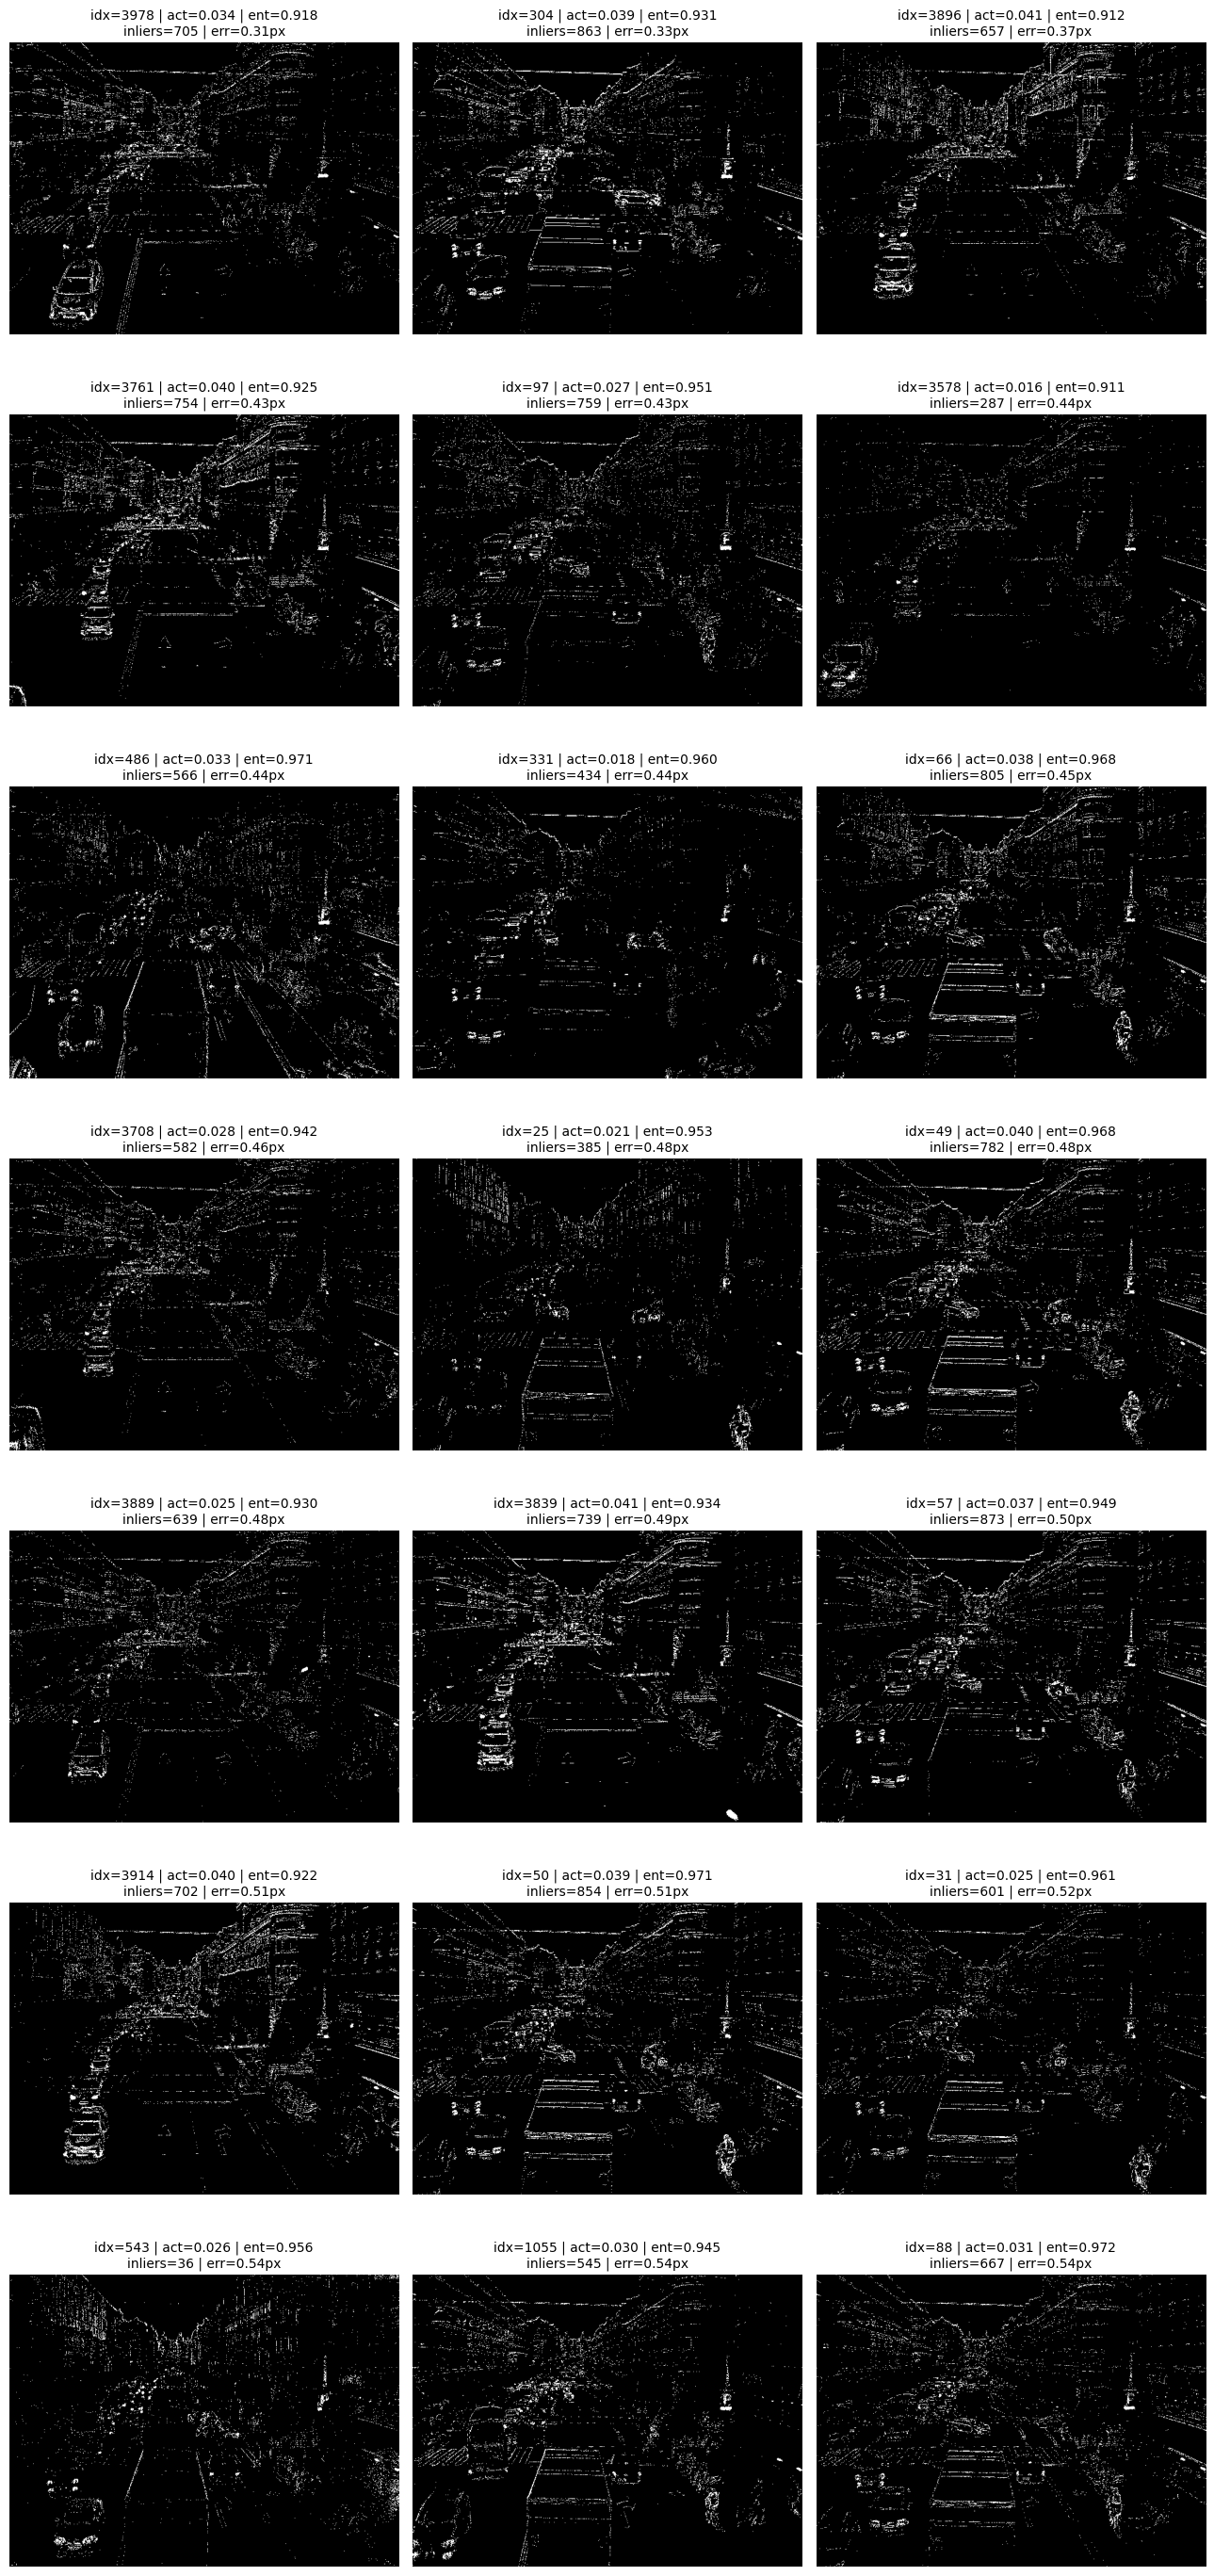

In [20]:
# Pick the best threshold rule by default, or manually override these values.
if len(threshold_results) > 0:
    best = threshold_results.iloc[0]
    A_MIN, A_MAX = best.activity_min, best.activity_max
    E_MIN, E_MAX = best.entropy_min, best.entropy_max
else:
    A_MIN, A_MAX = 0.05, 0.40
    E_MIN, E_MAX = 0.85, 0.96

selected = frame_quality[
    frame_quality["valid_h"].fillna(False) &
    (frame_quality["activity"] >= A_MIN) & (frame_quality["activity"] <= A_MAX) &
    (frame_quality["entropy"] >= E_MIN) & (frame_quality["entropy"] <= E_MAX)
].sort_values("median_alignment_error_px")

print(f"Selected {len(selected)} homographies with activity=[{A_MIN:.4f},{A_MAX:.4f}], entropy=[{E_MIN:.4f},{E_MAX:.4f}]")
display(selected[["frame_idx", "activity", "entropy", "num_inliers", "mean_reproj_px", "median_alignment_error_px", "mean_iou_to_consensus"]].head(30))

n = min(21, len(selected))
cols = 3
rows = math.ceil(n / cols) if n else 1
fig, axes = plt.subplots(rows, cols, figsize=(13, 4 * rows))
axes = np.array(axes).reshape(-1)
for ax_i, ax in enumerate(axes):
    ax.axis("off")
    if ax_i >= n:
        continue
    r = selected.iloc[ax_i]
    idx = int(r.frame_idx)
    ax.imshow(frames[idx], cmap="gray")
    ax.set_title(
        f"idx={idx} | act={r.activity:.3f} | ent={r.entropy:.3f}\n"
        f"inliers={r.num_inliers:.0f} | err={r.median_alignment_error_px:.2f}px",
        fontsize=10,
    )
plt.tight_layout()
plt.show()

## 10. Visual sanity check: one label transferred by multiple homographies

Use this to visually confirm that low-error homographies overlay labels consistently.

Missing
Missing
Missing
Missing
Missing


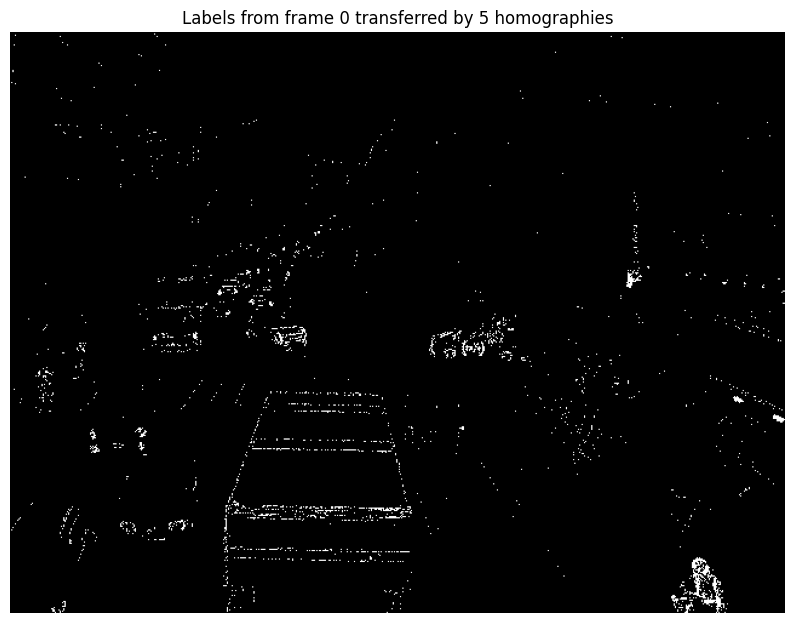

In [23]:
def draw_transferred_labels_for_frame(label_frame_idx, homography_frame_indices, max_labels=20):
    label_path = Path(LABEL_DIR) / f"{label_frame_idx}.txt"
    labels = read_yolo_label_file(label_path, LABEL_CONF_THRESHOLD)[:max_labels]
    if not labels:
        print("No labels found for", label_path)
        return

    h_lookup = {int(r.frame_idx): int(i) for i, r in frame_stats.reset_index(drop=True).iterrows()}
    vis = event_to_gray_uint8(frames[min(int(label_frame_idx), len(frames)-1)])
    vis = cv2.cvtColor(vis, cv2.COLOR_GRAY2BGR)

    for h_frame_idx in homography_frame_indices:
        if int(h_frame_idx) not in h_lookup:
            continue
        H = Hs[h_lookup[int(h_frame_idx)]]
        for lab in labels:
            src = yolo_box_to_corners(lab["x"], lab["y"], lab["w"], lab["h"], W_source, H_source)
            dst = transform_corners(src, H)
            if dst is None or not box_inside_frame(dst, W_target, H_target, pad=0):
                print("Missing")
                continue
            pts = np.round(dst).astype(np.int32).reshape(-1, 1, 2)
            cv2.polylines(vis, [pts], isClosed=True, color=(255, 255, 255), thickness=1)

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Labels from frame {label_frame_idx} transferred by {len(homography_frame_indices)} homographies")
    ax.axis("off")
    plt.show()

# Example: use a label frame with labels, and the top 5 selected homographies.
example_label_files = sorted(Path(LABEL_DIR).glob("*.txt"), key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem)
example_label_idx = int(example_label_files[0].stem) if example_label_files else 0
example_h_idxs = selected["frame_idx"].head(5).astype(int).tolist() if len(selected) else frame_quality.dropna(subset=["median_alignment_error_px"]).sort_values("median_alignment_error_px")["frame_idx"].head(5).astype(int).tolist()
draw_transferred_labels_for_frame(example_label_idx, example_h_idxs, max_labels=20)

## Notes / interpretation

- Lower `median_alignment_error_px` means this homography agrees better with the consensus of other valid homographies.
- Higher `mean_iou_to_consensus` means transferred boxes overlap the consensus better.
- `mean_reproj_px` is an internal feature-match/RANSAC quality measure; it can be useful but is not the same as label alignment quality.
- If the consensus itself is noisy, tighten the validity criteria, for example `MIN_INLIERS_FOR_VALID_H`, or restrict the threshold sweep to homographies with low reprojection error.
- For a first quick run, set `FRAME_INDICES_TO_PROCESS = range(0, T, 5)` and `MAX_LABEL_FRAMES = 500`; for final stats, set both to `None`.